# Bewegen Änderungen der US-Wetterprognose den Henry-Hub-Erdgaspreis?

**Stand der Daten:** 12.11.2026 · **Preis:** NG=F (Frontmonat-Future, Yahoo Finance) und Henry-Hub-Spot (EIA) · **Wetter:** Open-Meteo (ERA5-Archiv, GFS-Prognosen früherer Läufe)

Das Fazit steht ganz unten in Abschnitt 9. Dieses Notebook liest die Rohdaten aus `data/`; `fetch_data.py` lädt sie neu.

## 1 Daten und Datenprobleme

| Quelle | Inhalt | Zeitraum | Auffälligkeit |
|---|---|---|---|
| `datasets/natural-gas` `daily.csv` | Henry-Hub-**Spotpreis** der EIA | 1997 bis 11.11.2026 | Das ist nicht NG=F, sondern der Preis für physische Lieferung am Folgetag. 1997 bis 2006 lückenhaft (60 bis 140 Werte je Jahr), ab 2008 vollständig. |
| Yahoo Finance `NG=F` | fortlaufender Frontmonat-Future, Tagesschluss | 2015 bis 12.11.2026 | Zusätzlich geladen, weil die Frage auf NG=F zielt. Enthält Rollsprünge (Abschnitt 4). |
| Open-Meteo Archive API | stündliche 2-m-Temperatur (ERA5) für 7 Städte | 1991 bis 12.11.2026 | Lückenlos. 1991 bis 2015 dient nur als Klimanormal. |
| Open-Meteo Previous Runs API, Modell `gfs_global` | Prognosen mit 1 bis 7 Tagen Vorlauf | **ab 24.03.2021** (Vorlauf 1 Tag), ab 30.03.2021 (Vorlauf 7 Tage) | **Lücke 30.12.2023 bis 19.01.2024** (Vorlauf 7: bis 25.01.2024), mitten im Kälteeinbruch Januar 2024. Nicht füllbar. |

**Was die Dokumentation sagt** (open-meteo.com/en/docs/previous-runs-api, abgerufen 13.11.2026): „Most models are archived from January 2024“, Ausnahmen mit längerer Historie sind „GFS 2 m temperature — available from March 2021“ und JMA ab 2018. ECMWF IFS liefert laut Test erst ab 04.02.2024 Werte. Deshalb nutzt die Analyse GFS: Nur damit gibt es fünf Heizsaisons und sechs Sommer.

Folge für die Aufgabe: Wetterbeobachtungen gibt es ab 2016, **Prognoserevisionen erst ab Ende März 2021**. „Trainiere bis 2023“ bedeutet für Revisionen also knapp drei Jahre Training (zwei volle Heizsaisons plus Nov/Dez 2023).

In [1]:
import json, warnings
import numpy as np, pandas as pd, statsmodels.api as sm
import matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:.3f}".format)

BLAU, ORANGE, GRAU, TINTE = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b"   # Heizsaison, Kühlsaison, neutral, Text
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9, "axes.labelcolor": "#52514e",
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": TINTE,
    "legend.frameon": False, "legend.fontsize": 8.5, "font.family": "DejaVu Sans"})

CITIES = ["New York", "Chicago", "Houston", "Boston", "Atlanta", "Detroit", "Philadelphia"]
obs = pd.read_csv("data/obs_hourly.csv.gz", index_col=0, parse_dates=True)             # °F, Zeit in UTC
fc = pd.read_csv("data/fc_hourly_gfs_global.csv.gz", index_col=0, parse_dates=True)   # Spalten "Stadt|Vorlauf"
spot = pd.read_csv("data/prices.csv", parse_dates=["Date"]).dropna().set_index("Date").Price["2015-12-01":]
_r = json.load(open("data/ngf_yahoo.json"))["chart"]["result"][0]
_t = pd.to_datetime(_r["timestamp"], unit="s").tz_localize("UTC").tz_convert("America/New_York").tz_localize(None).normalize()
fut = pd.Series(_r["indicators"]["quote"][0]["close"], _t).dropna()
fut = fut[~fut.index.duplicated(keep="last")]["2015-12-01":]

print(f"Future NG=F: {len(fut)} Handelstage, {fut.index[0].date()} bis {fut.index[-1].date()}")
print(f"Spot (EIA):  {len(spot)} Handelstage, {spot.index[0].date()} bis {spot.index[-1].date()}")
print("Erster Prognosewert je Vorlauf:", {n: str(fc[f'New York|{n}'].first_valid_index().date()) for n in (1, 7)})
_s = fc["New York|1"].loc["2021-03-24":fut.index[-1]]; _na = _s[_s.isna()]
print(f"Prognoselücke: {_na.index[0]} bis {_na.index[-1]} ({len(_na)} Stunden)")
print("Mittlerer absoluter Prognosefehler New York nach Vorlauf (°F):",
      [round((fc[f'New York|{n}'] - obs['New York']).abs().mean(), 1) for n in range(1, 8)])

Future NG=F: 2755 Handelstage, 2015-12-01 bis 2026-11-12
Spot (EIA):  2758 Handelstage, 2015-12-01 bis 2026-11-11
Erster Prognosewert je Vorlauf: {1: '2021-03-24', 7: '2021-03-30'}
Prognoselücke: 2023-12-30 00:00:00 bis 2024-01-19 11:00:00 (492 Stunden)
Mittlerer absoluter Prognosefehler New York nach Vorlauf (°F): [np.float64(2.9), np.float64(3.1), np.float64(3.3), np.float64(3.7), np.float64(4.1), np.float64(4.6), np.float64(5.1)]


Der Prognosefehler wächst mit dem Vorlauf von knapp 3 °F auf gut 5 °F. Das passt zu echten Prognosen und spricht dafür, dass die Vorlauf-Spalten das enthalten, was sie versprechen.

## 2 Gewichte der Städte

Erdgas wird im Winter vor allem zum Heizen verbrannt, im Sommer in Gaskraftwerken für den Strom der Klimaanlagen. Deshalb zwei Gewichtungen:

- **HDD (Heizen): Einwohner der Metropolregion × Anteil der Haushalte mit Gasheizung.** Chicago und Detroit heizen zu rund 80 % mit Gas und zählen stärker, Houston und Atlanta (viel Strom) schwächer.
- **CDD (Kühlen): nur Einwohner.** Kühlbedarf läuft über Strom, und der Gasanteil der Stromerzeugung ist in allen sieben Regionen hoch.

Die Einwohnerzahlen sind die Metropolregionen laut Zensus 2020 (gerundet). Die Gasheizungs-Anteile sind **gerundete Näherungen aus dem Gedächtnis** (American Community Survey, Bundesstaat bzw. Metro) und nicht frisch nachgeschlagen, weil census.gov und eia.gov in dieser Umgebung nicht freigegeben sind. Abschnitt 8 zeigt, dass reine Einwohnergewichte das Ergebnis nicht ändern.

Einschränkung: Sieben Städte decken Nordosten, Mittleren Westen und einen Teil des Südens ab. Der Westen, die Plains und der restliche Süden fehlen. Profi-Indizes gewichten alle Regionen nach Gasverbrauch.

In [2]:
POP = pd.Series([20.1, 9.6, 7.1, 4.9, 6.1, 4.4, 6.2], CITIES)        # Mio. Einwohner Metropolregion, Zensus 2020
GAS = pd.Series([0.62, 0.80, 0.38, 0.52, 0.45, 0.80, 0.55], CITIES)  # Anteil Haushalte mit Gasheizung (Näherung)
W_H = POP * GAS / (POP * GAS).sum(); W_C = POP / POP.sum()
pd.DataFrame({"Einwohner Mio.": POP, "Gasheizung": GAS, "Gewicht HDD": W_H, "Gewicht CDD": W_C}).round(3)

,Einwohner Mio.,Gasheizung,Gewicht HDD,Gewicht CDD
New York,20.100,0.620,0.355,0.344
Chicago,9.600,0.800,0.219,0.164
Houston,7.100,0.380,0.077,0.122
Boston,4.900,0.520,0.073,0.084
Atlanta,6.100,0.450,0.078,0.104
Detroit,4.400,0.800,0.100,0.075
Philadelphia,6.200,0.550,0.097,0.106


## 3 Von Temperaturen zu Revisionen, ohne Blick in die Zukunft

**Was die API liefert:** `temperature_2m_previous_dayN` ist für jede Stunde der Wert, den ein Modelllauf mindestens N×24 Stunden vorher vorhergesagt hat.

**Stichzeit.** Jeder Tag *d* bekommt eine Stichzeit. Der „Prognosestand *d*“ besteht aus sieben 24-Stunden-Blöcken ab der Stichzeit; Block *N* nimmt die Spalte mit Vorlauf *N*. Dadurch stammt jeder Wert aus einem Lauf, der **vor** der Stichzeit gestartet wurde:

- **Future: Stichzeit 18:00 UTC.** Jüngster enthaltener Lauf ist der 12-UTC-Lauf, veröffentlicht gegen 16:30 UTC. Das Settlement ist um 14:30 New Yorker Zeit (18:30 bzw. 19:30 UTC). Der Prognosestand ist also vor dem Schlusskurs bekannt.
- **Spot: Stichzeit 12:00 UTC.** Jüngster Lauf ist 06 UTC (veröffentlicht gegen 10 UTC), der physische Handel für den Folgetag läuft danach am US-Vormittag.

**Gradtage** je Stadt und Block: HDD = max(0, 65 °F − T), CDD = max(0, T − 65 °F), mit T als 24-Stunden-Mittel; danach gewichtete Summe über die Städte.

**Revision am Tag *d*** = Summe über die sechs Zieltage, die im Stand *d* und im Stand *d*−1 vorkommen: Gradtage laut Stand *d* minus Gradtage laut Stand *d*−1 für denselben Zieltag. Positiv heißt bei HDD „kälter als gestern gedacht“, bei CDD „heißer als gestern gedacht“.

**Vergleichsgrößen (reiner Temperaturwert):**
- *Niveau*: Summe der Prognose-Gradtage der nächsten 7 Tage minus Klimanormal, Stand Vortag.
- *Beobachtet*: Gradtage des letzten abgeschlossenen 24-Stunden-Blocks minus Klimanormal.

Das Klimanormal ist der Tagesmittelwert 1991 bis 2015 (15 Tage geglättet), liegt also vollständig vor dem Testzeitraum.

**Handelstage.** Revisionen von Wochenenden und Feiertagen werden dem nächsten Handelstag zugeschlagen (Summe über alle Kalendertage seit dem letzten Handelstag), so wie der Markt die Nachrichten des Wochenendes am Montag verarbeitet. Fehlt in einem solchen Fenster ein Prognosewert, entfällt der Tag.

In [3]:
hdd = lambda T: (65 - T).clip(lower=0)
cdd = lambda T: (T - 65).clip(lower=0)

def build(px, origin_h, drop_roll=False, w_h=W_H, w_c=W_C):
    """Tagesdatensatz für eine Preisreihe. origin_h = Stichzeit in UTC-Stunden."""
    sh = pd.Timedelta(hours=origin_h)
    def blocks(h):                               # 24h-Blöcke ab Stichzeit, nur vollständige
        g = (h.index - sh).normalize()
        return h.groupby(g).mean().where(h.groupby(g).count() == 24)
    def normal(s):                               # Klimanormal 1991-2015 je Kalendertag
        doy = s[:"2015-12-31"].groupby(s[:"2015-12-31"].index.dayofyear).mean()
        return pd.concat([doy] * 3).rolling(15, center=True).mean().iloc[len(doy):2 * len(doy)]
    norm = lambda idx, n: n.reindex(idx.dayofyear).values
    F = {N: blocks(fc[[f"{c}|{N}" for c in CITIES]].set_axis(CITIES, axis=1)) for N in range(1, 8)}
    days = pd.date_range("2021-03-24", px.index[-1])
    idx = px.index
    def to_td(s, how="sum"):                     # Kalendertage -> nächster Handelstag
        lab = pd.Series(idx, idx).reindex(s.index, method="bfill"); g = s.groupby(lab.values)
        out = g.sum(min_count=1) if how == "sum" else g.last()
        return out.where(s.isna().groupby(lab.values).sum() == 0).reindex(idx)
    D = pd.DataFrame({"ret": np.log(px).diff() * 100, "gap": idx.to_series().diff().dt.days})
    if drop_roll:                                # erste Rendite nach Verfall vergleicht zwei Kontrakte
        pos = D.ret.groupby(idx.to_period("M")).cumcount(ascending=False)
        D["roll"] = pos == 1; D.loc[D.roll, "ret"] = np.nan
    for s, fun, w in [("H", hdd, w_h), ("C", cdd, w_c)]:
        V = {}                                   # V[N]: Gradtage für Zieltag d+N-1 laut Stand d
        for N in range(1, 8):
            v = (fun(F[N]) * w).sum(axis=1, min_count=7); v.index = v.index - pd.Timedelta(days=N - 1); V[N] = v
        V = pd.DataFrame(V).reindex(days)
        ob = (fun(blocks(obs)) * w).sum(axis=1, min_count=7); n = normal(ob)
        anom = pd.DataFrame({N: V[N] - norm(V.index + pd.Timedelta(days=N - 1), n) for N in range(1, 8)})
        rev = lambda a, b: sum(V[N] - V[N + 1].shift(1) for N in range(a, b + 1))
        D["rev" + s] = to_td(rev(1, 6))                      # Revision, Zieltage 1-6
        D["revN" + s] = to_td(rev(1, 3)); D["revF" + s] = to_td(rev(4, 6))
        D["lv" + s] = to_td(anom.sum(axis=1, skipna=False), "last").shift(1)   # Niveau, Stand Vortag
        oa = pd.Series(ob.values - norm(ob.index, n), ob.index)
        D["ob" + s] = to_td(oa.shift(1, freq="D"), "last")   # letzter abgeschlossener Block
    D["season"] = np.select([idx.month.isin([11, 12, 1, 2, 3]), idx.month.isin([6, 7, 8])], ["Heizsaison", "Kühlsaison"], "Übergang")
    lo, hi = D.ret.quantile([0.01, 0.99]); D["ret_w"] = D.ret.clip(lo, hi)   # gestutzt auf 1./99. Perzentil
    return D

DF = build(fut, 18, drop_roll=True)   # Future, Rolltage entfernt
DS = build(spot, 12)                  # Spot
DF.loc["2021-04":, ["ret", "revH", "revC", "lvH", "obH"]].describe().T[["count", "mean", "std", "min", "max"]]

,count,mean,std,min,max
ret,1347.000,-0.013,4.471,-29.645,38.173
revH,1398.000,-0.239,4.422,-32.412,25.860
revC,1398.000,0.052,2.789,-14.274,14.610
lvH,1399.000,-14.176,26.136,-102.911,90.062
obH,1415.000,-1.612,5.174,-20.028,19.267


## 4 Preise, Handelstage, Rollover

- **Rendite** = Differenz der logarithmierten Schlusskurse zweier aufeinanderfolgender Handelstage, in Prozent. Über ein Wochenende sind das drei Kalendertage; die Wetterrevisionen werden entsprechend aufsummiert.
- **Rollover.** NG=F ist kein einzelner Kontrakt, sondern immer der nächstfällige. Ein Monatskontrakt läuft drei Geschäftstage vor Monatsende aus. Am Tag danach zeigt Yahoo den nächsten Monat, die „Rendite“ dieses Tages vergleicht also zwei verschiedene Kontrakte. Im Herbst ist der Folgemonat teurer (Winteraufschlag), im Frühjahr billiger. Die Zelle unten zeigt den Effekt: Der vorletzte Handelstag des Monats hat im Schnitt die doppelte absolute Rendite. **Diese Tage werden entfernt.**
- **Was bleibt:** In den letzten Tagen vor Verfall ist der Frontmonat dünn gehandelt und schwankt stärker; der Markt handelt dann schon den Folgemonat. Wer das sauber lösen will, braucht Einzelkontrakte (z. B. immer den zweiten Monat) statt NG=F.
- **Spot** hat keinen Rollover, dafür extreme Sprünge bei Kälteeinbrüchen (Januar 2024: +143 % und −140 % innerhalb von vier Tagen). Der Spotpreis ist der Preis für Gas *morgen* und hängt am Wetter von morgen, nicht an der Überraschung.

In [4]:
fr = np.log(fut).diff() * 100
pos = fr.groupby(fr.index.to_period("M")).cumcount(ascending=False)
t = pd.DataFrame({"mittlere |Rendite| %": fr.abs().groupby(pos).mean(), "mittlere Rendite %": fr.groupby(pos).mean()}).head(6)
t.index = ["letzter Handelstag", "vorletzter (erster Tag im neuen Kontrakt)", "drittletzter (Verfall)", "4.-letzter", "5.-letzter", "6.-letzter"]
print(t.round(2).to_string())
print("\nEntfernte Rolltage seit April 2021:", int(DF.loc["2021-04":, "roll"].sum()))
print("Beobachtungen mit Revision:", DF.dropna(subset=["ret", "revH"]).groupby("season").size().to_dict())

                                           mittlere |Rendite| %  mittlere Rendite %
letzter Handelstag                                        2.810              -0.200
vorletzter (erster Tag im neuen Kontrakt)                 5.800               0.800
drittletzter (Verfall)                                    3.440               0.660
4.-letzter                                                2.580               0.410
5.-letzter                                                2.880               0.290
6.-letzter                                                2.730              -0.160

Entfernte Rolltage seit April 2021: 68
Beobachtungen mit Revision: {'Heizsaison': 487, 'Kühlsaison': 366, 'Übergang': 482}


## 5 Revision gegen Rendite

Regression je Saison:

Rendite(t) = a + b₋₁·Rev(t+1) + b₀·Rev(t) + b₁·Rev(t−1) + b₂·Rev(t−2) + b₃·Rev(t−3) + Monat + Wochentag + Rendite(t−1) + Fehler

- Heizsaison (Nov bis Mär) mit HDD-Revision, Kühlsaison (Jun bis Aug) mit CDD-Revision.
- Revision in Standardabweichungen: b ist die Preisänderung in Prozent je „üblich großer“ Revision.
- Monats-Dummies fangen Saisonalität ab, Wochentags-Dummies den Montagseffekt, die verzögerte Rendite die Autokorrelation. Standardfehler nach Newey-West (HAC, 5 Lags).
- **Rev(t+1)** ist eine Kontrolle: Die Revision von morgen darf die heutige Rendite nicht erklären, sonst steckt ein Zeitfehler in den Daten oder der Markt weiß mehr als GFS.
- Lag 0 ist gleichzeitig (erklärt, ist aber nicht handelbar). **Lag 1 bis 3 wäre handelbar**: Revision bekannt, Preis bewegt sich erst danach.

In [5]:
def controls(d):
    C = pd.get_dummies(d.index.month, prefix="m", drop_first=True).set_index(d.index)
    C = C.join(pd.get_dummies(d.index.dayofweek, prefix="wt", drop_first=True).set_index(d.index))
    C["ret_l1"] = d.ret.shift(1)
    return C.loc[:, C.nunique() > 1]

def ols(y, X, lags=5):
    Z = pd.concat([y, X], axis=1).dropna()
    return sm.OLS(Z.iloc[:, 0], sm.add_constant(Z.iloc[:, 1:].astype(float))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

LAGS = range(-1, 4)
def lag_reg(D, season, var, y="ret", lags=LAGS):
    sd = D.loc[D.season == season, var].std()
    X = pd.DataFrame({f"L{k}": D[var].shift(k) for k in lags}) / sd
    d = D.join(X); d = d[d.season == season]
    m = ols(d[y], pd.concat([d[X.columns], controls(d)], axis=1))
    return m, list(X.columns), d

rows, LAGFIT = [], {}
for name, D in [("Future", DF), ("Spot", DS)]:
    for season, var in [("Heizsaison", "revH"), ("Kühlsaison", "revC")]:
        for y in ["ret", "ret_w"]:
            m, cols, d = lag_reg(D, season, var, y)
            LAGFIT[name, season, y] = (m, cols)
            m4, c4, _ = lag_reg(D, season, var, y, range(0, 4))
            R = np.zeros((1, len(m4.params))); R[0, [list(m4.params.index).index(c) for c in c4]] = 1
            tt = m4.t_test(R)
            rows.append({"Preis": name, "Saison": season, "Rendite": "roh" if y == "ret" else "gestutzt", "n": int(m.nobs),
                **{f"b{c[1:]} (t)": f"{m.params[c]:+.2f} ({m.tvalues[c]:+.1f})" for c in cols},
                "Summe Lag 0-3 (t)": f"{float(np.ravel(tt.effect)[0]):+.2f} ({float(np.ravel(tt.tvalue)[0]):+.1f})",
                "p gemeinsam": round(float(m4.wald_test(",".join(f"{c}=0" for c in c4), scalar=True).pvalue), 3)})
pd.DataFrame(rows).set_index(["Preis", "Saison", "Rendite"])

n       b-1 (t)        b0 (t)        b1 (t)        b2 (t)        b3 (t) Summe Lag 0-3 (t)  p gemeinsam
Preis  Saison     Rendite                                                                                                           
Future Heizsaison roh       454  +0.37 (+1.4)  +0.37 (+0.9)  +0.82 (+2.6)  +0.39 (+1.7)  +0.03 (+0.1)      +1.59 (+2.3)        0.053
                  gestutzt  454  +0.24 (+1.2)  +0.29 (+1.1)  +0.60 (+2.4)  +0.40 (+1.9)  -0.02 (-0.1)      +1.25 (+2.2)        0.083
       Kühlsaison roh       348  +0.28 (+1.5)  -0.03 (-0.2)  +0.34 (+1.7)  +0.03 (+0.1)  +0.10 (+0.6)      +0.36 (+0.9)        0.585
                  gestutzt  348  +0.25 (+1.4)  -0.02 (-0.1)  +0.32 (+1.6)  +0.05 (+0.3)  +0.12 (+0.8)      +0.40 (+1.1)        0.619
Spot   Heizsaison roh       498  +0.34 (+0.6)  +0.45 (+0.6)  +0.29 (+0.6)  +1.34 (+2.0)  +1.24 (+1.3)      +3.34 (+1.8)        0.288
                  gestutzt  498  +0.36 (+1.0)  +0.17 (+0.4)  +0.37 (+1.0)  +0.91 (+2.5)  +0.41 (+1.0)      +1.87 (+2.2)        0.110
       Kühlsaison roh       383  +0.32 (+1.2)  +0.31 (+1.1)  +0.47 (+2.0)  -0.08 (-0.3)  +0.38 (+1.6)      +0.97 (+2.0)        0.078
                  gestutzt  383  +0.28 (+1.1)  +0.24 (+0.9)  +0.45 (+2.0)  -0.06 (-0.2)  +0.43 (+1.9)      +0.97 (+2.0)        0.088

**Lesehilfe:** „+0,82 (+2,6)“ heißt: Eine um eine Standardabweichung kältere Prognose geht mit 0,82 % höherem Preis einher, t-Wert 2,6 (ab etwa 2 spricht man von statistisch auffällig). „p gemeinsam“ prüft alle vier Lags 0 bis 3 zusammen; unter 0,05 wäre überzeugend.

**Chart 1** zeigt die Rohdaten: Revision gegen Rendite am selben Tag und am Folgetag.

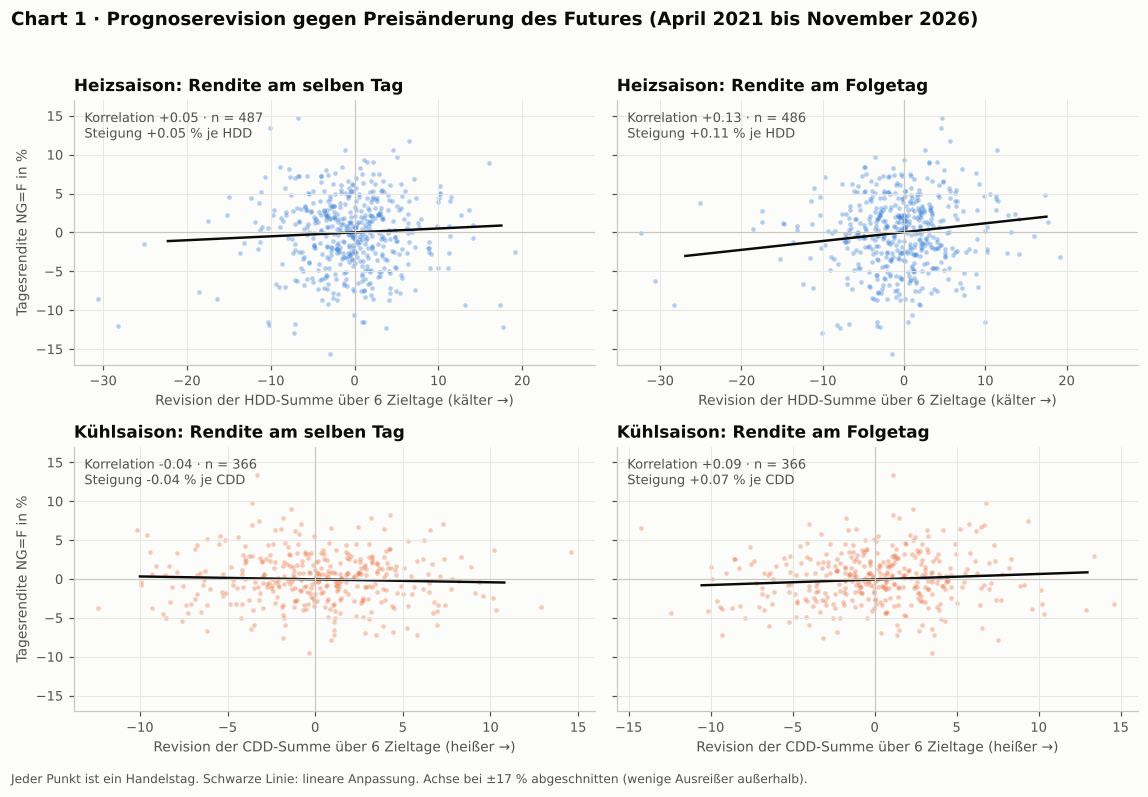

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2), sharey="row")
for i, (season, var, col, unit) in enumerate([("Heizsaison", "revH", BLAU, "HDD"), ("Kühlsaison", "revC", ORANGE, "CDD")]):
    for j, (k, lbl) in enumerate([(0, "Rendite am selben Tag"), (1, "Rendite am Folgetag")]):
        ax = axes[i, j]; d = DF[DF.season == season]
        x = DF[var].shift(k)[d.index]; z = pd.concat([x, d.ret], axis=1).dropna(); z.columns = ["x", "y"]
        ax.scatter(z.x, z.y, s=9, color=col, alpha=0.35, linewidths=0)
        b, a = np.polyfit(z.x, z.y, 1); xs = np.array([z.x.quantile(0.005), z.x.quantile(0.995)])
        ax.plot(xs, a + b * xs, color=TINTE, lw=1.6)
        ax.axhline(0, color="#c9c8c2", lw=0.8); ax.axvline(0, color="#c9c8c2", lw=0.8)
        ax.set_title(f"{season}: {lbl}")
        ax.text(0.02, 0.96, f"Korrelation {z.x.corr(z.y):+.2f} · n = {len(z)}\nSteigung {b:+.2f} % je {unit}", transform=ax.transAxes, va="top", fontsize=8.5, color="#52514e")
        ax.set_xlabel(f"Revision der {unit}-Summe über 6 Zieltage ({'kälter' if unit == 'HDD' else 'heißer'} →)")
        if j == 0: ax.set_ylabel("Tagesrendite NG=F in %")
        ax.set_ylim(-17, 17)
fig.suptitle("Chart 1 · Prognoserevision gegen Preisänderung des Futures (April 2021 bis November 2026)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.005, "Jeder Punkt ist ein Handelstag. Schwarze Linie: lineare Anpassung. Achse bei ±17 % abgeschnitten (wenige Ausreißer außerhalb).", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.02, 1, 0.96)); plt.show()

Die Punktwolken sind fast rund. Die Linie steigt leicht, aber die Streuung ist um ein Vielfaches größer als der Zusammenhang.

**Chart 2** zeigt die Regressionskoeffizienten je Verzögerung mit 95-%-Intervall.

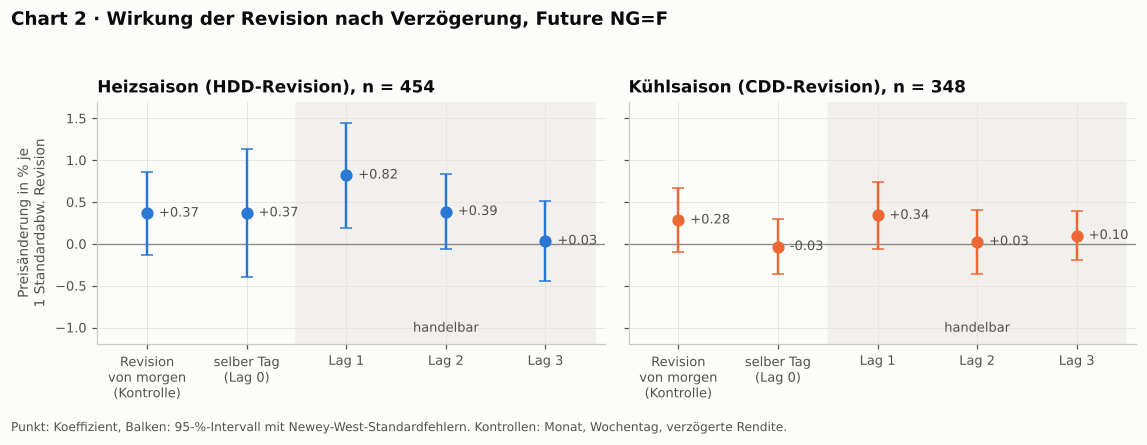

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for ax, (season, col) in zip(axes, [("Heizsaison", BLAU), ("Kühlsaison", ORANGE)]):
    m, cols = LAGFIT["Future", season, "ret"]
    b = m.params[cols].values; se = m.bse[cols].values; x = np.arange(len(cols))
    ax.axhline(0, color="#8a8984", lw=0.9)
    ax.errorbar(x, b, yerr=1.96 * se, fmt="o", color=col, ms=7, lw=1.6, capsize=4)
    for xi, bi, si in zip(x, b, se): ax.text(xi + 0.12, bi, f"{bi:+.2f}", va="center", fontsize=8.5, color="#52514e")
    ax.set_xticks(x); ax.set_xticklabels(["Revision\nvon morgen\n(Kontrolle)", "selber Tag\n(Lag 0)", "Lag 1", "Lag 2", "Lag 3"])
    ax.axvspan(1.5, 4.5, color="#f1f0ec", zorder=0); ax.text(3, ax.get_ylim()[0] if False else -1.05, "handelbar", ha="center", fontsize=8.5, color="#52514e")
    ax.set_title(f"{season} ({'HDD' if season == 'Heizsaison' else 'CDD'}-Revision), n = {int(m.nobs)}"); ax.set_xlim(-0.5, 4.6)
axes[0].set_ylabel("Preisänderung in % je\n1 Standardabw. Revision"); axes[0].set_ylim(-1.2, 1.7)
fig.suptitle("Chart 2 · Wirkung der Revision nach Verzögerung, Future NG=F", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.0, "Punkt: Koeffizient, Balken: 95-%-Intervall mit Newey-West-Standardfehlern. Kontrollen: Monat, Wochentag, verzögerte Rendite.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 0.94)); plt.show()

## 6 Revision oder reiner Temperaturwert?

Hypothese: Der Preis reagiert auf Überraschungen (Revision), nicht auf das Niveau. Jede Größe wird einzeln zur Regression aus Abschnitt 5 (nur Kontrollen) hinzugefügt. „ΔR²“ ist der zusätzlich erklärte Anteil der Renditeschwankung. Rendite gestutzt, damit einzelne Ausreißer nicht entscheiden.

Die beobachtete Temperatur gibt es seit 2016, deshalb steht sie zweimal da: im selben Zeitraum wie die Revision und über die volle Zeit.

In [8]:
def horse(D, season, s):
    d = D[D.season == season]; out = []
    specs = [("Revision heute (Zieltage 1-6)", "rev" + s, 0), ("  davon Zieltage 1-3", "revN" + s, 0), ("  davon Zieltage 4-6", "revF" + s, 0),
             ("Revision gestern (Lag 1)", "rev" + s, 1), ("Revision Summe 3 Tage (Lag 0-2)", "rev" + s, "sum"),
             ("Niveau: 7-Tage-Prognose minus Normal", "lv" + s, 0), ("Beobachtet minus Normal, ab 2021", "ob" + s, 0), ("Beobachtet minus Normal, ab 2016", "ob" + s, "long")]
    for lbl, v, k in specs:
        x = D[v].rolling(3).sum() if k == "sum" else D[v].shift(k if isinstance(k, int) else 0)
        x = x[d.index]
        if k != "long": x = x.where(d["rev" + s].notna())
        x = (x / x.std()).rename("x")
        m = ols(d.ret_w, pd.concat([x, controls(d)], axis=1))
        m0 = ols(d.ret_w.loc[m.model.data.row_labels], controls(d).loc[m.model.data.row_labels])
        out.append({"Saison": season, "Größe": lbl, "n": int(m.nobs), "b (% je 1 SD)": m.params["x"], "t": m.tvalues["x"], "p": m.pvalues["x"], "ΔR²": m.rsquared - m0.rsquared})
    return out
H = {name: pd.DataFrame(horse(D, "Heizsaison", "H") + horse(D, "Kühlsaison", "C")).set_index(["Saison", "Größe"]) for name, D in [("Future", DF), ("Spot", DS)]}
print("FUTURE NG=F"); display(H["Future"].round(3))
print("SPOT (EIA)"); display(H["Spot"].round(3))

FUTURE NG=F


n  b (% je 1 SD)      t     p   ΔR²
Saison     Größe                                                                       
Heizsaison Revision heute (Zieltage 1-6)          461          0.293  1.061 0.289 0.004
             davon Zieltage 1-3                   461         -0.101 -0.417 0.677 0.000
             davon Zieltage 4-6                   461          0.359  1.326 0.185 0.006
           Revision gestern (Lag 1)               459          0.579  2.431 0.015 0.014
           Revision Summe 3 Tage (Lag 0-2)        457          0.748  2.547 0.011 0.022
           Niveau: 7-Tage-Prognose minus Normal   461          0.427  1.653 0.098 0.008
           Beobachtet minus Normal, ab 2021       461          0.477  1.919 0.055 0.010
           Beobachtet minus Normal, ab 2016      1008          0.030  0.206 0.837 0.000
Kühlsaison Revision heute (Zieltage 1-6)          348         -0.101 -0.571 0.568 0.001
             davon Zieltage 1-3                   348         -0.011 -0.061 0.951 0.000
             davon Zieltage 4-6                   348         -0.109 -0.692 0.489 0.001
           Revision gestern (Lag 1)               348          0.278  1.455 0.146 0.007
           Revision Summe 3 Tage (Lag 0-2)        348          0.131  0.818 0.413 0.001
           Niveau: 7-Tage-Prognose minus Normal   348         -0.479 -2.421 0.015 0.018
           Beobachtet minus Normal, ab 2021       348         -0.412 -1.944 0.052 0.015
           Beobachtet minus Normal, ab 2016       641         -0.246 -1.844 0.065 0.007

SPOT (EIA)


n  b (% je 1 SD)      t     p   ΔR²
Saison     Größe                                                                       
Heizsaison Revision heute (Zieltage 1-6)          506          0.210  0.510 0.610 0.001
             davon Zieltage 1-3                   506         -0.497 -1.428 0.153 0.004
             davon Zieltage 4-6                   506          0.445  1.075 0.282 0.003
           Revision gestern (Lag 1)               504          0.354  0.998 0.318 0.002
           Revision Summe 3 Tage (Lag 0-2)        502          0.798  1.998 0.046 0.009
           Niveau: 7-Tage-Prognose minus Normal   506         -0.079 -0.171 0.864 0.000
           Beobachtet minus Normal, ab 2021       506         -1.168 -2.630 0.009 0.020
           Beobachtet minus Normal, ab 2016      1118         -0.846 -3.005 0.003 0.015
Kühlsaison Revision heute (Zieltage 1-6)          383          0.172  0.641 0.522 0.001
             davon Zieltage 1-3                   383          0.331  1.005 0.315 0.004
             davon Zieltage 4-6                   383          0.021  0.082 0.935 0.000
           Revision gestern (Lag 1)               383          0.330  1.445 0.148 0.004
           Revision Summe 3 Tage (Lag 0-2)        383          0.217  0.907 0.364 0.002
           Niveau: 7-Tage-Prognose minus Normal   383         -0.237 -1.137 0.255 0.002
           Beobachtet minus Normal, ab 2021       383         -0.165 -0.817 0.414 0.001
           Beobachtet minus Normal, ab 2016       707         -0.006 -0.041 0.967 0.000

## 7 Stabilität über die Zeit und Saisonvergleich

**Chart 3:** rollierende Korrelation über 120 Handelstage zwischen der Rendite und der Revision der letzten drei Tage. Für eine ganzjährige Reihe werden HDD- und CDD-Revision addiert (beides bedeutet mehr Gasbedarf). Das graue Band zeigt, was bei reinem Zufall zu erwarten wäre.

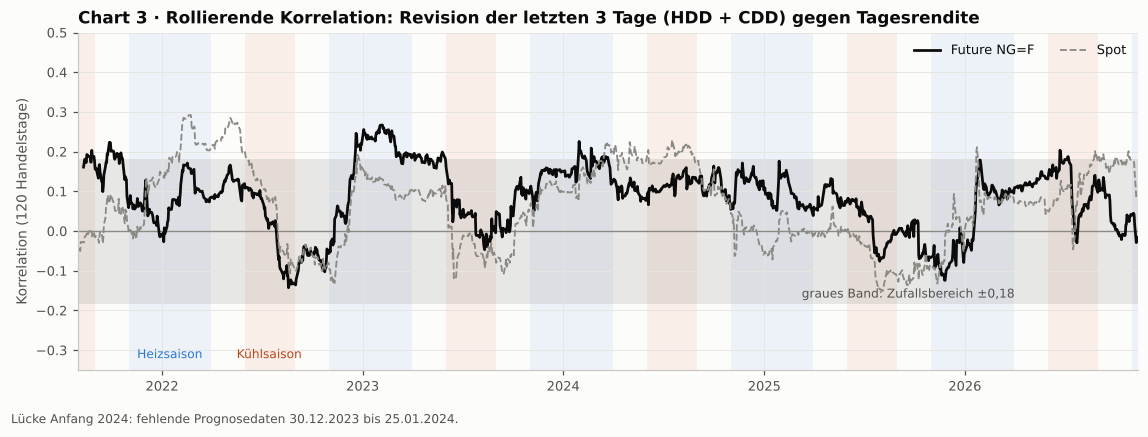

In [9]:
tdd = (DF.revH + DF.revC).rolling(3).sum()
rc = DF.ret_w.rolling(120, min_periods=90).corr(tdd)
rc_s = DS.ret_w.rolling(120, min_periods=90).corr((DS.revH + DS.revC).rolling(3).sum())
fig, ax = plt.subplots(figsize=(10.5, 3.9))
for y in range(2021, 2027):
    ax.axvspan(pd.Timestamp(f"{y}-11-01"), pd.Timestamp(f"{y+1}-03-31"), color=BLAU, alpha=0.07, lw=0)
    ax.axvspan(pd.Timestamp(f"{y}-06-01"), pd.Timestamp(f"{y}-08-31"), color=ORANGE, alpha=0.09, lw=0)
ax.axhspan(-2 / np.sqrt(120), 2 / np.sqrt(120), color="#8a8984", alpha=0.18, lw=0)
ax.axhline(0, color="#8a8984", lw=0.9)
ax.plot(rc.index, rc, color=TINTE, lw=1.8, label="Future NG=F"); ax.plot(rc_s.index, rc_s, color=GRAU, lw=1.2, ls="--", label="Spot")
ax.set_xlim(pd.Timestamp("2021-08-01"), DF.index[-1]); ax.set_ylim(-0.35, 0.5); ax.set_ylabel("Korrelation (120 Handelstage)")
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper right", ncol=2)
ax.text(pd.Timestamp("2025-03-10"), -0.175, "graues Band: Zufallsbereich ±0,18", fontsize=8, color="#52514e", va="bottom")
ax.text(pd.Timestamp("2022-01-15"), -0.32, "Heizsaison", fontsize=8, color=BLAU, ha="center"); ax.text(pd.Timestamp("2022-07-15"), -0.32, "Kühlsaison", fontsize=8, color="#b8491c", ha="center")
ax.set_title("Chart 3 · Rollierende Korrelation: Revision der letzten 3 Tage (HDD + CDD) gegen Tagesrendite")
fig.text(0.01, 0.0, "Lücke Anfang 2024: fehlende Prognosedaten 30.12.2023 bis 25.01.2024.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

**Chart 4:** Gesamtwirkung einer Revision (Summe der Koeffizienten Lag 0 bis 3) je Saison, für Future und Spot. In der Übergangszeit (Apr, Mai, Sep, Okt) wird die addierte HDD+CDD-Revision verwendet.

,Preis,Saison,n,Summe,se,t
0,Future,Heizsaison,455,1.250,0.570,2.220
1,Future,Kühlsaison,348,0.400,0.380,1.060
2,Future,Übergang,458,0.360,0.340,1.080
3,Spot,Heizsaison,500,1.870,0.850,2.220
4,Spot,Kühlsaison,383,0.970,0.490,1.990
5,Spot,Übergang,503,0.290,0.410,0.710


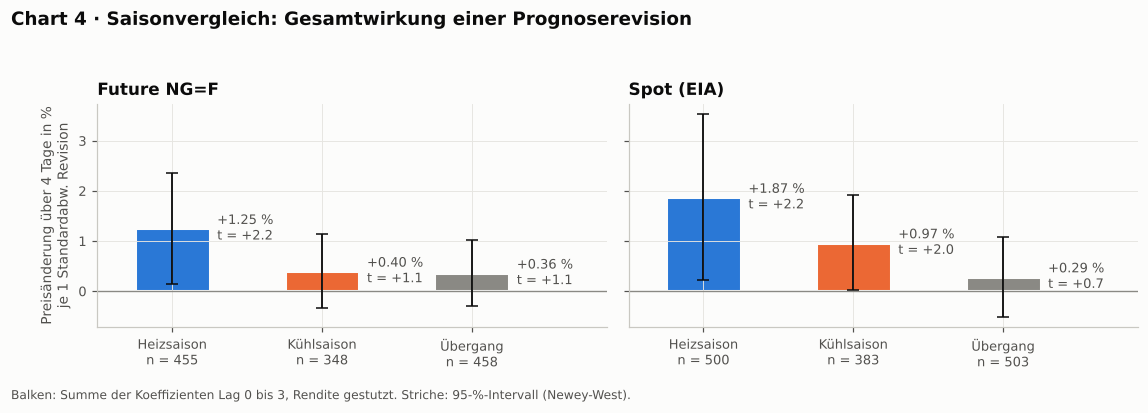

In [10]:
res = []
for name, D0 in [("Future", DF), ("Spot", DS)]:
    D = D0.copy(); D["revT"] = D.revH + D.revC
    for season, var in [("Heizsaison", "revH"), ("Kühlsaison", "revC"), ("Übergang", "revT")]:
        m, cols, _ = lag_reg(D, season, var, "ret_w", range(0, 4))
        R = np.zeros((1, len(m.params))); R[0, [list(m.params.index).index(c) for c in cols]] = 1; tt = m.t_test(R)
        res.append({"Preis": name, "Saison": season, "n": int(m.nobs), "Summe": float(np.ravel(tt.effect)[0]), "se": float(np.ravel(tt.sd)[0]), "t": float(np.ravel(tt.tvalue)[0])})
res = pd.DataFrame(res); display(res.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for ax, name in zip(axes, ["Future", "Spot"]):
    r = res[res.Preis == name].reset_index(drop=True); cols_ = [BLAU, ORANGE, GRAU]
    ax.axhline(0, color="#8a8984", lw=0.9)
    ax.bar(r.index, r.Summe, width=0.5, color=cols_, edgecolor="#fcfcfb", linewidth=2)
    ax.errorbar(r.index, r.Summe, yerr=1.96 * r.se, fmt="none", ecolor=TINTE, lw=1.2, capsize=4)
    for i, row in r.iterrows(): ax.text(i + 0.3, row.Summe, f"{row.Summe:+.2f} %\nt = {row.t:+.1f}", va="center", fontsize=8.5, color="#52514e")
    ax.set_xticks(r.index); ax.set_xticklabels([f"{s}\nn = {n}" for s, n in zip(r.Saison, r.n)]); ax.set_xlim(-0.5, 2.9)
    ax.set_title("Future NG=F" if name == "Future" else "Spot (EIA)")
axes[0].set_ylabel("Preisänderung über 4 Tage in %\nje 1 Standardabw. Revision")
fig.suptitle("Chart 4 · Saisonvergleich: Gesamtwirkung einer Prognoserevision", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.0, "Balken: Summe der Koeffizienten Lag 0 bis 3, Rendite gestutzt. Striche: 95-%-Intervall (Newey-West).", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 0.93)); plt.show()

## 8 Out-of-Sample: bis Ende 2023 schätzen, ab 2024 prüfen

Die Koeffizienten werden nur mit Daten bis 31.12.2023 geschätzt und dann unverändert auf 2024 bis November 2026 angewendet (ungestutzte Renditen, keine Kontrollen).

- **R² im Test** misst, ob das Modell besser ist als „Rendite = Durchschnitt der Trainingszeit“. Null oder negativ heißt: kein Mehrwert.
- **Handelsregel:** long, wenn das Modell eine überdurchschnittliche Rendite erwartet, sonst short. Nur die Varianten mit Lag ≥ 1 sind echte Prognosen. Ohne Handelskosten.

In [11]:
def oos(D, season, var, lags, split="2024-01-01"):
    sd = D.loc[(D.season == season) & (D.index < split), var].std()
    X = pd.DataFrame({f"L{k}": D[var].shift(k) for k in lags}) / sd
    d = D[["ret"]].join(X)[D.season == season].dropna()
    tr, te = d[d.index < split], d[d.index >= split]
    m = sm.OLS(tr.ret, sm.add_constant(tr[X.columns])).fit(); pred = m.predict(sm.add_constant(te[X.columns]))
    r2 = 1 - ((te.ret - pred) ** 2).sum() / ((te.ret - tr.ret.mean()) ** 2).sum()
    pnl = np.sign(pred - tr.ret.mean()) * te.ret
    return {"n Training": len(tr), "n Test": len(te), "R² Training": m.rsquared, "R² Test": r2, "Trefferquote": (pnl > 0).mean(),
            "Ø je Tag %": pnl.mean(), "t": pnl.mean() / pnl.std() * np.sqrt(len(pnl)), "Sharpe p.a.": pnl.mean() / pnl.std() * np.sqrt(252)}, pnl
rows, PNL = [], {}
for name, D in [("Future", DF), ("Spot", DS)]:
    for season, var in [("Heizsaison", "revH"), ("Kühlsaison", "revC")]:
        for lbl, lags in [("gleichzeitig (Lag 0), nicht handelbar", [0]), ("Prognose Lag 1", [1]), ("Prognose Lag 1+2", [1, 2])]:
            r, pnl = oos(D, season, var, lags); PNL[name, season, lbl] = pnl
            rows.append({"Preis": name, "Saison": season, "Modell": lbl, **r})
OOS = pd.DataFrame(rows).set_index(["Preis", "Saison", "Modell"]); OOS.round(3)

n Training  n Test  R² Training  R² Test  Trefferquote  Ø je Tag %      t  Sharpe p.a.
Preis  Saison     Modell                                                                                                                       
Future Heizsaison gleichzeitig (Lag 0), nicht handelbar         240     247        0.000    0.002         0.466       0.268  0.797        0.806
                  Prognose Lag 1                                240     246        0.020    0.012         0.484       0.226  0.670        0.678
                  Prognose Lag 1+2                              239     245        0.026    0.008         0.510       0.306  0.904        0.917
       Kühlsaison gleichzeitig (Lag 0), nicht handelbar         184     182        0.007   -0.017         0.478       0.037  0.161        0.190
                  Prognose Lag 1                                184     182        0.008    0.005         0.522       0.108  0.469        0.552
                  Prognose Lag 1+2                              184     182        0.010    0.003         0.511       0.079  0.344        0.404
Spot   Heizsaison gleichzeitig (Lag 0), nicht handelbar         250     256        0.001    0.001         0.527       1.209  1.207        1.197
                  Prognose Lag 1                                250     255        0.009   -0.002         0.471      -1.519 -1.515       -1.506
                  Prognose Lag 1+2                              249     254        0.017    0.005         0.469       0.702  0.696        0.693
       Kühlsaison gleichzeitig (Lag 0), nicht handelbar         193     190        0.001   -0.003         0.432      -0.173 -0.422       -0.486
                  Prognose Lag 1                                193     190        0.000    0.003         0.479       0.252  0.616        0.709
                  Prognose Lag 1+2                              193     190        0.001    0.006         0.421       0.203  0.496        0.571

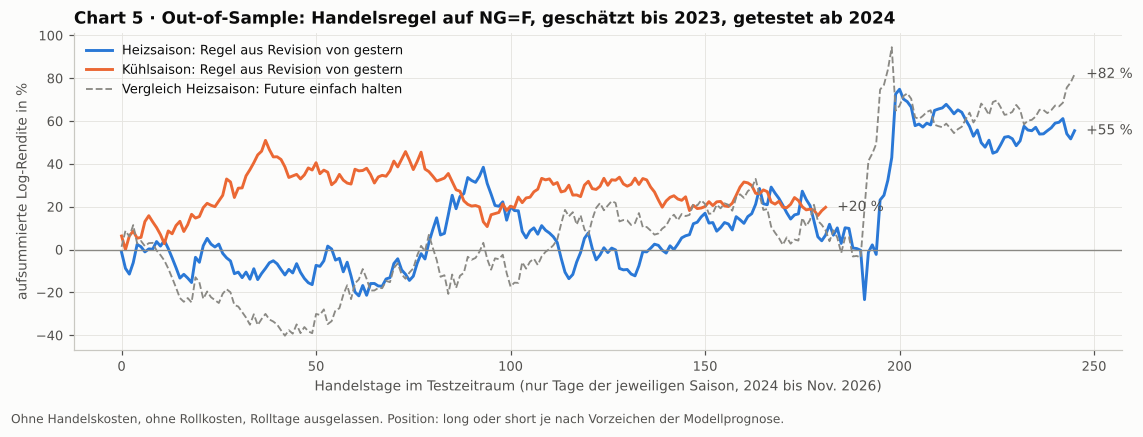

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 3.9))
for season, col in [("Heizsaison", BLAU), ("Kühlsaison", ORANGE)]:
    p = PNL["Future", season, "Prognose Lag 1"].cumsum()
    ax.plot(np.arange(len(p)), p.values, color=col, lw=1.9, label=f"{season}: Regel aus Revision von gestern")
    ax.text(len(p) + 2, p.values[-1], f"{p.values[-1]:+.0f} %", color="#52514e", fontsize=9, va="center")
bh = DF.loc[PNL["Future", "Heizsaison", "Prognose Lag 1"].index, "ret"].cumsum()
ax.plot(np.arange(len(bh)), bh.values, color=GRAU, lw=1.2, ls="--", label="Vergleich Heizsaison: Future einfach halten")
ax.text(len(bh) + 2, bh.values[-1], f"{bh.values[-1]:+.0f} %", color="#52514e", fontsize=9, va="center")
ax.axhline(0, color="#8a8984", lw=0.9); ax.set_xlabel("Handelstage im Testzeitraum (nur Tage der jeweiligen Saison, 2024 bis Nov. 2026)"); ax.set_ylabel("aufsummierte Log-Rendite in %")
ax.legend(loc="upper left"); ax.set_title("Chart 5 · Out-of-Sample: Handelsregel auf NG=F, geschätzt bis 2023, getestet ab 2024")
fig.text(0.01, 0.0, "Ohne Handelskosten, ohne Rollkosten, Rolltage ausgelassen. Position: long oder short je nach Vorzeichen der Modellprognose.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

In [13]:
p = PNL["Future", "Heizsaison", "Prognose Lag 1"]
top = p.sort_values(ascending=False).head(5)
print(f"Gewinn der Heizsaison-Regel im Test: {p.sum():+.0f} % über {len(p)} Tage")
print(f"Davon die 5 besten Tage: {top.sum():+.0f} %  ({', '.join(d.strftime('%d.%m.%Y') for d in top.index)})")
print(f"Ohne diese 5 Tage: {p.sum() - top.sum():+.0f} %")

Gewinn der Heizsaison-Regel im Test: +55 % über 246 Tage
Davon die 5 besten Tage: +100 %  (02.02.2026, 26.01.2026, 21.01.2026, 21.02.2024, 23.12.2025)
Ohne diese 5 Tage: -44 %


### Robustheit
Gleiche Regression wie in Abschnitt 5 (Future, Heizsaison, gestutzte Rendite), jeweils eine Annahme geändert.

In [14]:
variants = {"Basis (Stichzeit 18 UTC, Rolltage raus, Gasgewichte)": DF,
            "Rolltage nicht entfernt": build(fut, 18, drop_roll=False),
            "Stichzeit 06 UTC statt 18 UTC": build(fut, 6, drop_roll=True),
            "HDD nach Einwohnern statt Gasheizung": build(fut, 18, True, w_h=W_C),
            "alle Städte gleich gewichtet": build(fut, 18, True, w_h=pd.Series(1 / 7, CITIES), w_c=pd.Series(1 / 7, CITIES))}
rows = []
for lbl, D in variants.items():
    for season, var in [("Heizsaison", "revH"), ("Kühlsaison", "revC")]:
        m, cols, _ = lag_reg(D, season, var, "ret_w")
        rows.append({"Variante": lbl, "Saison": season, "n": int(m.nobs), **{f"b{c[1:]} (t)": f"{m.params[c]:+.2f} ({m.tvalues[c]:+.1f})" for c in cols}})
pd.DataFrame(rows).set_index(["Variante", "Saison"])

n       b-1 (t)        b0 (t)        b1 (t)        b2 (t)        b3 (t)
Variante                                           Saison                                                                               
Basis (Stichzeit 18 UTC, Rolltage raus, Gasgewi... Heizsaison  454  +0.24 (+1.2)  +0.29 (+1.1)  +0.60 (+2.4)  +0.40 (+1.9)  -0.02 (-0.1)
                                                   Kühlsaison  348  +0.25 (+1.4)  -0.02 (-0.1)  +0.32 (+1.6)  +0.05 (+0.3)  +0.12 (+0.8)
Rolltage nicht entfernt                            Heizsaison  505  +0.27 (+1.4)  +0.37 (+1.4)  +0.64 (+2.7)  +0.55 (+2.8)  +0.19 (+0.9)
                                                   Kühlsaison  384  +0.26 (+1.5)  +0.09 (+0.5)  +0.32 (+1.7)  +0.01 (+0.1)  +0.19 (+1.2)
Stichzeit 06 UTC statt 18 UTC                      Heizsaison  453  +0.36 (+1.7)  +0.44 (+1.6)  +0.37 (+1.5)  +0.37 (+2.0)  +0.12 (+0.5)
                                                   Kühlsaison  348  +0.12 (+0.8)  +0.10 (+0.6)  +0.17 (+0.9)  -0.01 (-0.1)  +0.30 (+1.9)
HDD nach Einwohnern statt Gasheizung               Heizsaison  454  +0.22 (+1.1)  +0.27 (+1.0)  +0.61 (+2.5)  +0.39 (+1.9)  -0.03 (-0.1)
                                                   Kühlsaison  348  +0.25 (+1.4)  -0.02 (-0.1)  +0.32 (+1.6)  +0.05 (+0.3)  +0.12 (+0.8)
alle Städte gleich gewichtet                       Heizsaison  454  +0.20 (+1.0)  +0.27 (+1.0)  +0.62 (+2.5)  +0.38 (+1.8)  -0.01 (-0.1)
                                                   Kühlsaison  348  +0.33 (+1.7)  +0.10 (+0.6)  +0.35 (+1.8)  +0.08 (+0.4)  +0.09 (+0.6)

## 9 Fazit in Alltagssprache

**Gibt es einen Zusammenhang?** Die Richtung stimmt, belastbar ist er nicht.

- **Winter (Nov bis Mär):** Wird die Prognose kälter, steigt der Gaspreis tendenziell. Eine übliche Revision (rund 6 Heizgradtage über sechs Tage, also etwa 1 °F kälter pro Tag) geht über vier Handelstage mit etwa **+1,3 bis +1,6 %** beim Future einher. Zum Vergleich: Der Future schwankt im Winter an einem normalen Tag um 4,5 %. Die Revision erklärt **rund 2 % der Preisbewegung**, 98 % kommen von anderswo.
- Statistisch ist das ein Grenzfall (t ≈ 2,2; gemeinsamer Test p = 0,05 bis 0,08). Bei fünf Wintern und mehreren getesteten Varianten kann so ein Wert auch Zufall sein.
- **Sommer (Jun bis Aug):** kein verlässlicher Effekt beim Future (+0,4 %, t ≈ 1).
- **Am selben Tag** ist der Effekt klein und nicht signifikant. Der größte Koeffizient liegt einen Tag später. Das ist ungewöhnlich für einen liquiden Markt und hat drei mögliche Erklärungen, zwischen denen diese Daten nicht entscheiden können: Zufall, eine Stunden-Unschärfe in der Zuordnung von Modelllauf und Schlusskurs, oder der Markt wartet auf Bestätigung durch andere Modelle.

**Überraschung oder Temperaturwert?** Die Hypothese wird schwach gestützt, nicht bewiesen.

- Beim **Future** hat der reine Temperaturwert keinen stabilen Effekt: Die beobachtete Abweichung vom Normal erklärt über 2016 bis 2026 nichts (t = 0,2). Die Revision der letzten drei Tage ist die beste Einzelgröße (t = 2,5), aber eben schwach.
- Beim **Spotpreis** ist es umgekehrt: Er hängt am tatsächlichen Wetter. Nach einem sehr kalten Tag fällt er am Folgetag wieder (−0,85 % je Standardabweichung, t = −3,0, 2016 bis 2026). Das ist das Abklingen von Kältespitzen bei physischer Lieferung, keine Reaktion auf Überraschungen.

**Ist das handelbar?** Nein.

- Im Test ab 2024 erklärt das Modell 0 bis 1 % der Rendite. Die Trefferquote der Handelsregel liegt bei 47 bis 52 %, also Münzwurf. Der Durchschnittsgewinn ist statistisch nicht von null zu unterscheiden (t < 1).
- Die Heizsaison-Regel steht im Test zwar mit +55 % im Plus, aber fünf einzelne Tage (vier davon im Winter 2025/26) bringen zusammen +100 %. Ohne sie steht die Regel bei −44 % (Zelle in Abschnitt 8). Das ist Glück an wenigen Extremtagen, kein System.
- Handelskosten, Rollkosten und die Hebelwirkung eines Futures, der täglich 4 bis 5 % schwankt, sind noch nicht abgezogen.

**Warum so wenig, obwohl jeder Gashändler aufs Wetter schaut?** Die Analyse sieht nur einen kleinen Ausschnitt dessen, was der Markt sieht:

1. Nur ein Modell (GFS-Hauptlauf). Der Markt handelt stark auf ECMWF und auf Ensembles; die gibt es bei Open-Meteo erst ab 2024.
2. Nur 1 bis 7 Tage Vorlauf. Für den Frontmonat zählt vor allem die Prognose für Tag 8 bis 15.
3. Nur sieben Städte statt eines landesweiten, nach Gasverbrauch gewichteten Index.
4. Nur Tagesschlusskurse. Der Preis reagiert binnen Minuten auf einen neuen Modelllauf, das verschwimmt im Tageswert.
5. Fünf Winter, davon fehlen drei Wochen im Januar 2024.

Ein schwaches Ergebnis hier heißt also nicht „Wetter ist dem Gaspreis egal“, sondern: **Mit frei verfügbaren Tagesdaten lässt sich der Effekt nur erahnen, und ein Handelsvorteil ist daraus nicht zu holen.**

**Offene Punkte**
- Die Gasheizungs-Anteile in den Gewichten sind Näherungen (Abschnitt 2); das Ergebnis hängt nicht daran.
- NG=F von Yahoo ist eine zusammengesetzte Reihe. Rolltage sind entfernt, die Tage kurz vor Verfall bleiben verzerrt.
- Die gestutzte Rendite nutzt Perzentile des Gesamtzeitraums; der Out-of-Sample-Test verwendet deshalb ungestutzte Renditen.